# Machine Learning Lab – Decision Tree Classifier

**Roll No.: CH.SC.U4CSE24257**


## 1. Import required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## 2. Create sample dataset

In [2]:
data = {
    'Age': [
        22, 25, 27, 29, 31, 32, 34, 35, 36, 38,
        40, 42, 45, 47, 50, 52, 55, 58, 60, 62,90,20,42
    ],
    'Income': [
        25000, 30000, 35000, 40000, 28000, 32000, 45000, 50000,
        35000, 55000, 40000, 60000, 45000, 70000, 50000, 80000,
        60000, 90000, 75000, 100000,20000,15000,210000
    ],
    'Buy_House': [
        'No', 'No', 'No', 'No',
        'Yes', 'No', 'Yes', 'Yes', 'No', 'Yes',
        'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',
        'Yes', 'Yes', 'Yes', 'Yes','Yes','No','No'
    ]
}

df = pd.DataFrame(data)

print("Dataset:")
print(df)

Dataset:
    Age  Income Buy_House
0    22   25000        No
1    25   30000        No
2    27   35000        No
3    29   40000        No
4    31   28000       Yes
5    32   32000        No
6    34   45000       Yes
7    35   50000       Yes
8    36   35000        No
9    38   55000       Yes
10   40   40000        No
11   42   60000       Yes
12   45   45000       Yes
13   47   70000       Yes
14   50   50000       Yes
15   52   80000       Yes
16   55   60000       Yes
17   58   90000       Yes
18   60   75000       Yes
19   62  100000       Yes
20   90   20000       Yes
21   20   15000        No
22   42  210000        No


## 3. Display dataset information

In [3]:
print("\nDataset Shape:", df.shape)
df.info()


Dataset Shape: (23, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Age        23 non-null     int64 
 1   Income     23 non-null     int64 
 2   Buy_House  23 non-null     object
dtypes: int64(2), object(1)
memory usage: 684.0+ bytes


## 4. Check for missing values

In [4]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Age          0
Income       0
Buy_House    0
dtype: int64


## 5. Display descriptive statistics

In [5]:
print("\nDescriptive Statistics:")
print(df.describe())


Descriptive Statistics:
             Age         Income
count  23.000000      23.000000
mean   42.260870   56086.956522
std    15.963644   40258.159019
min    20.000000   15000.000000
25%    31.500000   33500.000000
50%    40.000000   45000.000000
75%    51.000000   65000.000000
max    90.000000  210000.000000


## 6. Display target variable distribution

In [6]:
print("\nHouse Purchase Distribution:")
print(df['Buy_House'].value_counts())


House Purchase Distribution:
Buy_House
Yes    14
No      9
Name: count, dtype: int64


## 7. Convert target variable into numerical values

In [7]:
df['Buy_House_Code'] = df['Buy_House'].map({
    'No': 0,
    'Yes': 1
})

## 8. Define input and target variables

In [8]:
X = df[['Age', 'Income']]
y = df['Buy_House_Code']

print("\nInput Variables:")
print(X.head())

print("\nTarget Variable:")
print(y.head())


Input Variables:
   Age  Income
0   22   25000
1   25   30000
2   27   35000
3   29   40000
4   31   28000

Target Variable:
0    0
1    0
2    0
3    0
4    1
Name: Buy_House_Code, dtype: int64


## 9. Split data into training and testing sets

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


Training Samples: 18
Testing Samples: 5


## 10. Create and train the Decision Tree model

In [10]:
model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

print("\nDecision Tree Model trained successfully.")


Decision Tree Model trained successfully.


## 11. Display tree information

In [11]:
print("\nTree Depth:", model.get_depth())
print("Number of Leaves:", model.get_n_leaves())

print("\nFeature Importance:")

for feature, importance in zip(X.columns, model.feature_importances_):
    print(f"{feature}: {importance:.4f}")


Tree Depth: 3
Number of Leaves: 4

Feature Importance:
Age: 0.5860
Income: 0.4140


## 12. Make predictions

In [12]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Age': X_test['Age'].values,
    'Income': X_test['Income'].values,
    'Actual': y_test.values,
    'Predicted': y_pred
})

results['Actual'] = results['Actual'].map({
    0: 'No',
    1: 'Yes'
})

results['Predicted'] = results['Predicted'].map({
    0: 'No',
    1: 'Yes'
})

print("\nPredictions:")
print(results.to_string(index=False))


Predictions:
 Age  Income Actual Predicted
  47   70000    Yes       Yes
  40   40000     No        No
  58   90000    Yes       Yes
  29   40000     No        No
  35   50000    Yes       Yes


## 13. Calculate model accuracy

In [13]:
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")


Accuracy: 1.0
Accuracy Percentage: 100.0 %


## 14. Display confusion matrix


Confusion Matrix:
[[2 0]
 [0 3]]


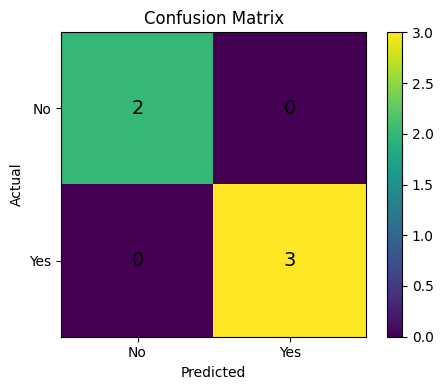

In [14]:
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(5, 4))
plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ['No', 'Yes'])
plt.yticks([0, 1], ['No', 'Yes'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=14)

plt.colorbar()
plt.tight_layout()
plt.show()

## 15. Display classification report

In [15]:
print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=['No', 'Yes'],
    zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         2
         Yes       1.00      1.00      1.00         3

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



## 16. Visualize the Decision Tree

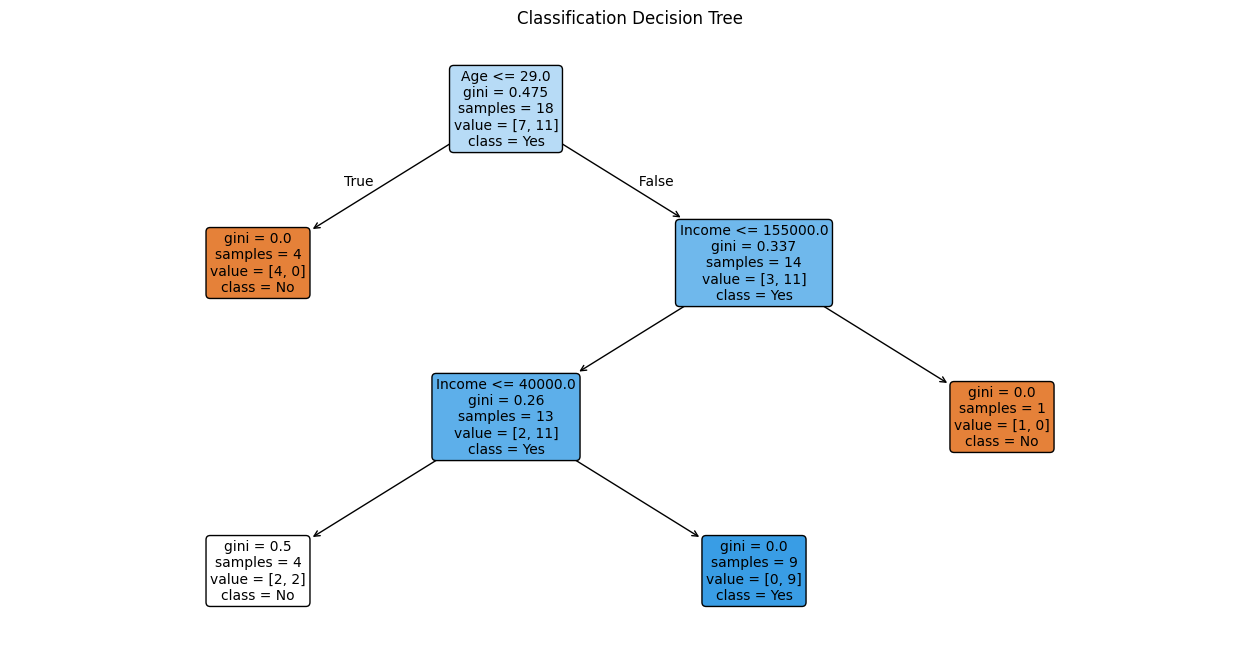

In [16]:
plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=['Age', 'Income'],
    class_names=['No', 'Yes'],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Classification Decision Tree")
plt.show()

## 17. Visualize Age and Income distribution

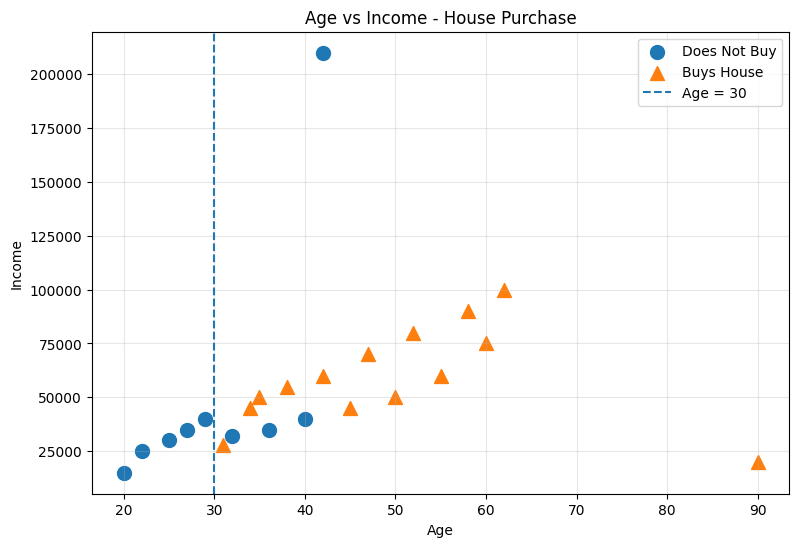

In [17]:
plt.figure(figsize=(9, 6))

for label, marker in [(0, 'o'), (1, '^')]:
    subset = df[df['Buy_House_Code'] == label]

    plt.scatter(
        subset['Age'],
        subset['Income'],
        label='Does Not Buy' if label == 0 else 'Buys House',
        marker=marker,
        s=100
    )

plt.axvline(
    x=30,
    linestyle='--',
    label='Age = 30'
)

plt.xlabel("Age")
plt.ylabel("Income")
plt.title("Age vs Income - House Purchase")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 18. Predict house purchase for new people

In [18]:
new_people = pd.DataFrame({
    'Age': [25, 35, 45, 55],
    'Income': [30000, 50000, 60000, 90000]
})

predictions = model.predict(new_people)
probabilities = model.predict_proba(new_people)[:, 1]

new_people['Predicted_Buy_House'] = np.where(
    predictions == 1,
    'Yes',
    'No'
)

new_people['Probability_of_Buying'] = probabilities

print("\nPredictions for New People:")
print(new_people.to_string(index=False))


Predictions for New People:
 Age  Income Predicted_Buy_House  Probability_of_Buying
  25   30000                  No                    0.0
  35   50000                 Yes                    1.0
  45   60000                 Yes                    1.0
  55   90000                 Yes                    1.0


## 19. Conclusion

In [19]:
print("\nDecision Tree classification was successfully implemented.")
print("The model predicts whether a person buys a house using Age and Income.")
print("The model was evaluated using accuracy, confusion matrix, and classification report.")
print("The decision tree was also visualized to understand the splitting process.")


Decision Tree classification was successfully implemented.
The model predicts whether a person buys a house using Age and Income.
The model was evaluated using accuracy, confusion matrix, and classification report.
The decision tree was also visualized to understand the splitting process.
